In [1]:
!pip install torch torchvision

In [ ]:
import torch
import torch.nn.functional as F  # Parameterless functions, like (some) activation functions
import torchvision.datasets as datasets  # Standard datasets
import torchvision.transforms as transforms  # Transformations we can perform on our dataset for augmentation
from torch import optim  # For optimizers like SGD, Adam, etc.
from torch import nn  # All neural network modules
from torch.utils.data import DataLoader
from tqdm import tqdm  # For nice progress bar!
import matplotlib.pyplot as plt

Load dataset
---

In [3]:
train_dataset = datasets.MNIST(root="dataset/",train=True, transform=transforms.ToTensor(),download=True)
test_dataset = datasets.MNIST(root="dataset/",train=False, transform=transforms.ToTensor(),download=True)

Randomly Printing some images

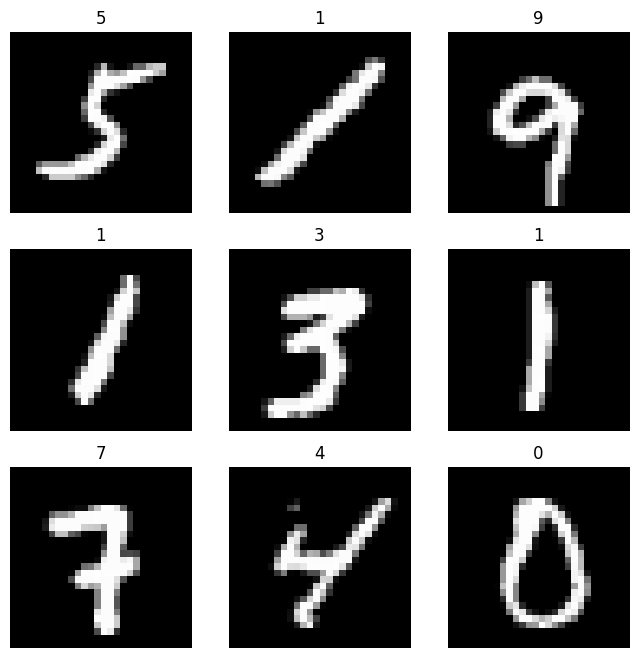

In [4]:
label_map ={
    0: "0",
    1: "1",
    2: "2",
    3: "3",
    4: "4",
    5: "5",
    6: "6",
    7: "7",
    8: "8",
    9: "9",
}
figure = plt.figure(figsize=(8,8))
cols,rows =3,3
for i in range(1,cols*rows+1):
    sample_idx = torch.randint(len(train_dataset),size=(1,)).item()
    img, label = train_dataset[sample_idx]
    figure.add_subplot(rows,cols,i)
    plt.title(label_map[label])
    plt.axis("off")
    plt.imshow(img.squeeze(),cmap='gray')
plt.show()

Just one batch process

In [5]:
batch_size =1
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size,shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size,shuffle=False)

Neural Network
-

In [ ]:
torch.manual_seed(24)
class SimpleNN(nn.Module):
    def __init__(self,in_channels=1,num_classes=10):
        super(SimpleNN,self).__init__()
        self.fc1 = nn.Linear(784,500) # 784 = input layer, 500 = hidden layer, 10 = outer layer
        self.fc2 = nn.Linear(500,num_classes)

    def forward(self,x):
        #print("Input:", x.shape)
        x=x.reshape(x.shape[0],-1)  # flattening
        #print("After Flattening:", x.shape)
        x=self.fc1(x)
        x=self.fc2(x)
        #print("Output:", x.shape)
        return x

Setting the device (CPU/GPU)
---

In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu") # CUDA -> GPU
device

device(type='cpu')

Hyper-Parameters
----

In [8]:
in_channels = 1
num_classes = 10
learning_rate = 0.01
num_epochs = 3

Processing of a single batch
---

In [9]:
model = SimpleNN(in_channels=in_channels,num_classes=num_classes)
train_features, train_labels = next(iter(train_loader))
model(train_features)

tensor([[ 0.2771, -0.0034,  0.0237, -0.0183, -0.2195, -0.1692, -0.0579,  0.0603,
          0.0580,  0.0035]], grad_fn=<AddmmBackward0>)

Feature batch Shape: torch.Size([1, 1, 28, 28])
Labels batch shape: torch.Size([1])


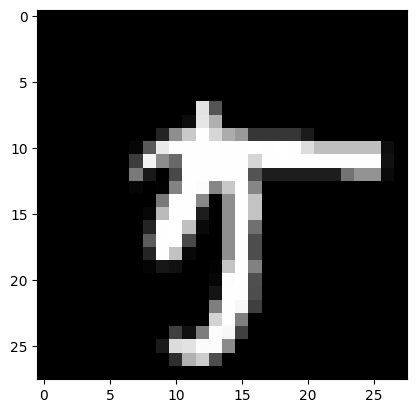

Label: 5


In [10]:
# Display image and label.

print(f"Feature batch Shape: {train_features.size()}")
print(f"Labels batch shape: {train_labels.size()}")
img = train_features[0].squeeze()
label = train_labels[0]
plt.imshow(img,cmap='gray')
plt.show()
print(f"Label: {label}")

All the Batches
---

In [11]:
batch_size =16
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size,shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size,shuffle=False)

Initialize the network
---

In [12]:
model = SimpleNN(in_channels=in_channels,num_classes=num_classes).to(device)

Loss And Optimizer
-----

In [13]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)
optimizer

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    weight_decay: 0
)

Train Network
-

In [14]:
for epoch in range(num_epochs):
    for batch_idx, (data,targets) in enumerate(tqdm(train_loader)):
        # get data to cuda if possible
        data =data.to(device=device)
        targets = targets.to(device=device)

        # forward
        scores =model(data)
        loss = criterion(scores,targets)
    
        # zero gradients, perform a backward pass and update the weights
        optimizer.zero_grad()

        # perform a backward pass (backpropagation)
        loss.backward()

        # update the parameters
        optimizer.step()
    if epoch%100==0: 
        print('epoch:', epoch+1, 'loss:', loss.item())

100%|██████████| 3750/3750 [00:25<00:00, 146.72it/s]


epoch: 1 loss: 3.056577205657959


100%|██████████| 3750/3750 [00:26<00:00, 142.66it/s]


##### Check accuracy on training & test to see how good our model

In [15]:
def check_accuracy(loader, model):
    num_correct = 0
    num_samples = 0
    model.eval()

    with torch.no_grad():
        for x, y in loader:
            x = x.to(device=device)
            y = y.to(device=device)

            scores = model(x)
            _, predictions = scores.max(1)
            num_correct += (predictions == y).sum()
            num_samples += predictions.size(0)

    model.train()
    return num_correct / num_samples


In [16]:
print(f"Accuracy on training set: {check_accuracy(train_loader, model)*100:.2f}")
print(f"Accuracy on test set: {check_accuracy(test_loader, model)*100:.2f}")

Accuracy on training set: 86.52
Accuracy on test set: 86.56
